# Intent classifier: TF-IDF + Logistic Regression

Same idea as the transaction classifier: character n-grams + logistic regression. Character n-grams handle Egyptian spelling, typos and Franco-Arabic without needing a tokenizer.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
import re

AR_DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789")

def normalize(text):
    text = str(text).translate(AR_DIGITS)
    text = re.sub("[إأآ]", "ا", text)
    text = text.replace("ى", "ي").replace("ة", "ه")
    text = re.sub(r"[\u064B-\u0652\u0640]", "", text)  # tashkeel + tatweel
    return text.lower().strip()

In [3]:
df = pd.read_csv("../../data/intent_dataset.csv")
df["clean"] = df["text"].apply(normalize)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.2, stratify=df["intent"], random_state=42
)
print("train:", len(X_train), " test:", len(X_test))

train: 1606  test: 402


### Which features work best?

In [4]:
def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)

def word_tfidf():
    return TfidfVectorizer(analyzer="word", ngram_range=(1, 2), sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")

options = {
    "word": word_tfidf(),
    "char": char_tfidf(),
    "char + word": FeatureUnion([("char", char_tfidf()), ("word", word_tfidf())]),
}

for name, features in options.items():
    model = Pipeline([
        ("tfidf", features),
        ("classifier", LogisticRegression(max_iter=3000, C=10, class_weight="balanced")),
    ])
    model.fit(X_train, y_train)
    print(f"{name:<12} accuracy: {accuracy_score(y_test, model.predict(X_test)):.3f}")

word         accuracy: 0.823


char         accuracy: 0.891


char + word  accuracy: 0.886


Char alone is as good as char + word and simpler, so we keep char.

In [5]:
intent_model = Pipeline([
    ("tfidf", char_tfidf()),
    ("classifier", LogisticRegression(max_iter=3000, C=10, class_weight="balanced")),
])
intent_model.fit(X_train, y_train)

y_pred = intent_model.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

Test Accuracy: 0.8905

                precision    recall  f1-score   support

        advice       0.86      0.93      0.89        45
      forecast       0.84      0.90      0.87        30
      greeting       0.97      0.97      0.97        32
        manage       0.88      0.86      0.87        42
        market       0.88      0.96      0.91        45
  out_of_scope       0.87      0.65      0.74        40
spending_query       0.88      0.82      0.85        56
   transaction       0.91      0.96      0.93       112

      accuracy                           0.89       402
     macro avg       0.89      0.88      0.88       402
  weighted avg       0.89      0.89      0.89       402



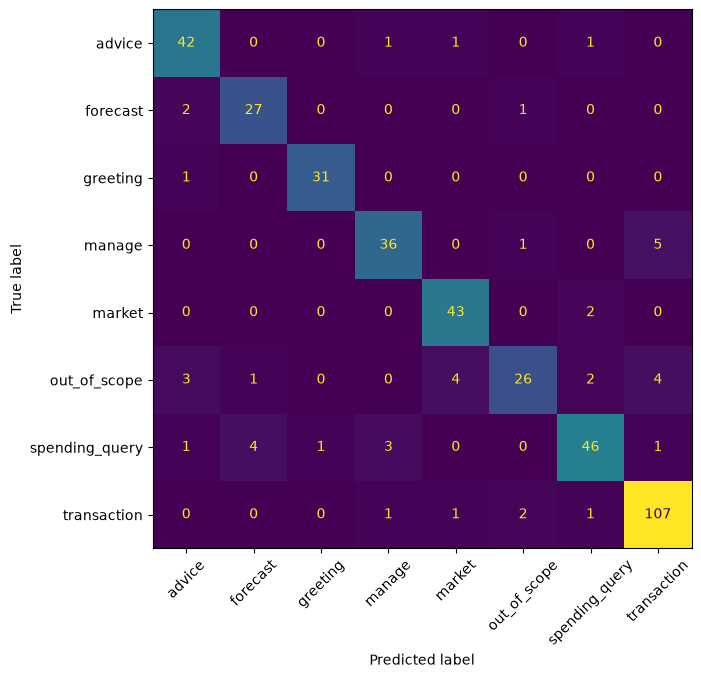

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=45, colorbar=False)
plt.show()

### Where does it go wrong?

In [7]:
errors = pd.DataFrame({"text": df.loc[X_test.index, "text"], "true": y_test, "predicted": y_pred})
errors = errors[errors["true"] != errors["predicted"]]
print(len(errors), "errors")
errors.groupby(["true", "predicted"]).size().sort_values(ascending=False).head(8)

44 errors


true            predicted   
manage          transaction     5
out_of_scope    market          4
                transaction     4
spending_query  forecast        4
                manage          3
out_of_scope    advice          3
forecast        advice          2
transaction     out_of_scope    2
dtype: int64

In [8]:
errors.head(15)

,text,true,predicted
1134,لا انا مقصتش اني صرفت ١٠٠٠ جنيه انا كنت بسأل بس,manage,transaction
1456,Padel match نصيبي 260 LE,transaction,out_of_scope
1006,الغى تحويل انستاباي ال 2000 جنيه ده معلق ومكملش,manage,transaction
741,3a2ed ozoon el khazana 12 shahr kam ba3d el da...,market,spending_query
1165,Remind me to pay my rent of 6000 EGP on the fi...,out_of_scope,transaction
348,How much freelance income am I likely to make ...,forecast,advice
854,الشتا هيدخل بجد امتى في مصر الجو لسه حر,out_of_scope,market
1399,List all expenses above 1000 EGP from the past...,spending_query,manage
346,When will all my ValU installments be fully pa...,forecast,out_of_scope
1140,فكرني يوم ٥ في الشهر أدفع قسط البنك ٣٠٠٠ جنيه,out_of_scope,transaction


What stands out:
- **out_of_scope** is the weakest (recall 0.65): random questions get confused with market, transaction or advice. It needs more examples.
- **manage → transaction**: "امسح ال 200" looks a lot like "دفعت 200".
- **spending_query vs forecast**: "هصرف كام" (future) and "صرفت كام" (past) only differ by a prefix.

### Future-tense rule

In [9]:
# "هصرف" (will spend) and "صرفت" (spent) look almost the same in char n-grams,
# so the model mixes up spending questions and forecasts. A future-tense verb fixes most of it.
FUTURE_RE = re.compile(
    r"(?:^|\s)(?:ه|هي|هن)(?:صرف|حوش|وفر|دفع|فضل|تبقي|كفي|خلص|قبض|يفضل|يتبقي|يكفي|يخلص)\w*"
    r"|\bwill i\b|\bam i going to\b|\bhow much will\b|\bha(?:sraf|7awesh|dfa3)\b|\bhayfdal\b",
    re.I,
)

In [10]:
def with_rule(texts, predictions):
    fixed = []
    for text, pred in zip(texts, predictions):
        if pred == "spending_query" and FUTURE_RE.search(text):
            pred = "forecast"
        fixed.append(pred)
    return np.array(fixed)

y_pred_rule = with_rule(X_test, y_pred)
print(f"before rule: {accuracy_score(y_test, y_pred):.4f}")
print(f"after rule:  {accuracy_score(y_test, y_pred_rule):.4f}")
# no change on this split, but it never makes things worse and it fixes the obvious cases below

for text in ["هصرف كام الشهر ده؟", "صرفت كام الشهر ده؟", "will I run out of money", "how much did I spend"]:
    print(text, "->", with_rule([normalize(text)], intent_model.predict([normalize(text)]))[0])

before rule: 0.8905
after rule:  0.8905
هصرف كام الشهر ده؟ -> forecast
صرفت كام الشهر ده؟ -> spending_query
will I run out of money -> forecast
how much did I spend -> spending_query


### When should the bot say "I'm not sure"?

If the top probability is low, it's better to ask the user than to guess.

In [11]:
probs = intent_model.predict_proba(X_test)
top = probs.max(axis=1)
pred = intent_model.classes_[probs.argmax(axis=1)]

rows = []
for threshold in [0.0, 0.3, 0.35, 0.4, 0.45, 0.5]:
    sure = top >= threshold
    rows.append({
        "threshold": threshold,
        "asks the user": f"{(~sure).mean():.1%}",
        "accuracy when it answers": f"{(pred[sure] == y_test.values[sure]).mean():.3f}",
    })
pd.DataFrame(rows)

,threshold,asks the user,accuracy when it answers
0,0.00,0.0%,0.891
1,0.30,4.7%,0.909
2,0.35,10.0%,0.928
3,0.40,14.9%,0.936
4,0.45,21.4%,0.953
5,0.50,26.1%,0.956


At 0.35 the bot asks the user in about 10% of messages, and accuracy on the rest goes from 89% to about 93%. Going higher makes it ask too often, so we use 0.35.

### Train on everything and save

In [12]:
final_model = Pipeline([
    ("tfidf", char_tfidf()),
    ("classifier", LogisticRegression(max_iter=3000, C=10, class_weight="balanced")),
])
final_model.fit(df["clean"], df["intent"])
joblib.dump(final_model, "../../models/intent_tfidf.joblib")
print("saved")

saved


In [13]:
examples = [
    "اشتريت لاب من مول البستان ب 5000 جنيه",
    "صرفت كام على الأكل الشهر ده؟",
    "هصرف كام الشهر ده؟",
    "الدولار بكام النهارده؟",
    "سهم CIB عامل ايه؟",
    "احوش ازاي من مرتبي؟",
    "امسح آخر حاجة",
    "ازيك",
    "عايز وصفة كشري",
]
clean = [normalize(t) for t in examples]
pd.DataFrame({
    "text": examples,
    "intent": with_rule(clean, final_model.predict(clean)),
    "confidence": final_model.predict_proba(clean).max(axis=1).round(2),
})

,text,intent,confidence
0,اشتريت لاب من مول البستان ب 5000 جنيه,transaction,0.96
1,صرفت كام على الأكل الشهر ده؟,spending_query,0.98
2,هصرف كام الشهر ده؟,forecast,0.80
3,الدولار بكام النهارده؟,market,0.94
4,سهم CIB عامل ايه؟,market,0.88
5,احوش ازاي من مرتبي؟,advice,1.00
6,امسح آخر حاجة,manage,0.98
7,ازيك,greeting,0.83
8,عايز وصفة كشري,out_of_scope,0.41
